# Hafta 11 · Görüntü Segmentasyonu

**Yapay Zekâya Giriş — Laboratuvar Defteri**  
Dr. Seda Bayat Toksöz · Iğdır Üniversitesi · 2026–2027 Güz

Bu defterde madeni paraları havza algoritmasıyla sayacak, PyTorch ile küçük bir U-Net kurup katman katman boyutlarını izleyecek, sentetik görüntülerde eğitip maske tahmin edecek, hazır segmentasyon modellerinin büyüklüklerini karşılaştıracak, Dice/IoU/mIoU hesaplayacak ve bağlantılı bileşenlerle nesne sayacaksınız.

Hücreleri yukarıdan aşağıya sırayla çalıştırın (**Shift + Enter**). Parametreleri değiştirip sonucun nasıl değiştiğini gözlemleyin.

In [1]:
# Grafik ayarları (ders notlarıyla aynı renk paleti)
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#E69F00", "#56B4E9", "#CC79A7"]),
})

## 1. Klasik yöntemler
### k-means ile renk tabanlı segmentasyon (Şekil 11.2)
Her piksel RGB uzayında bir noktadır; k-means pikselleri k renk kümesine ayırır.

(135300, 3)


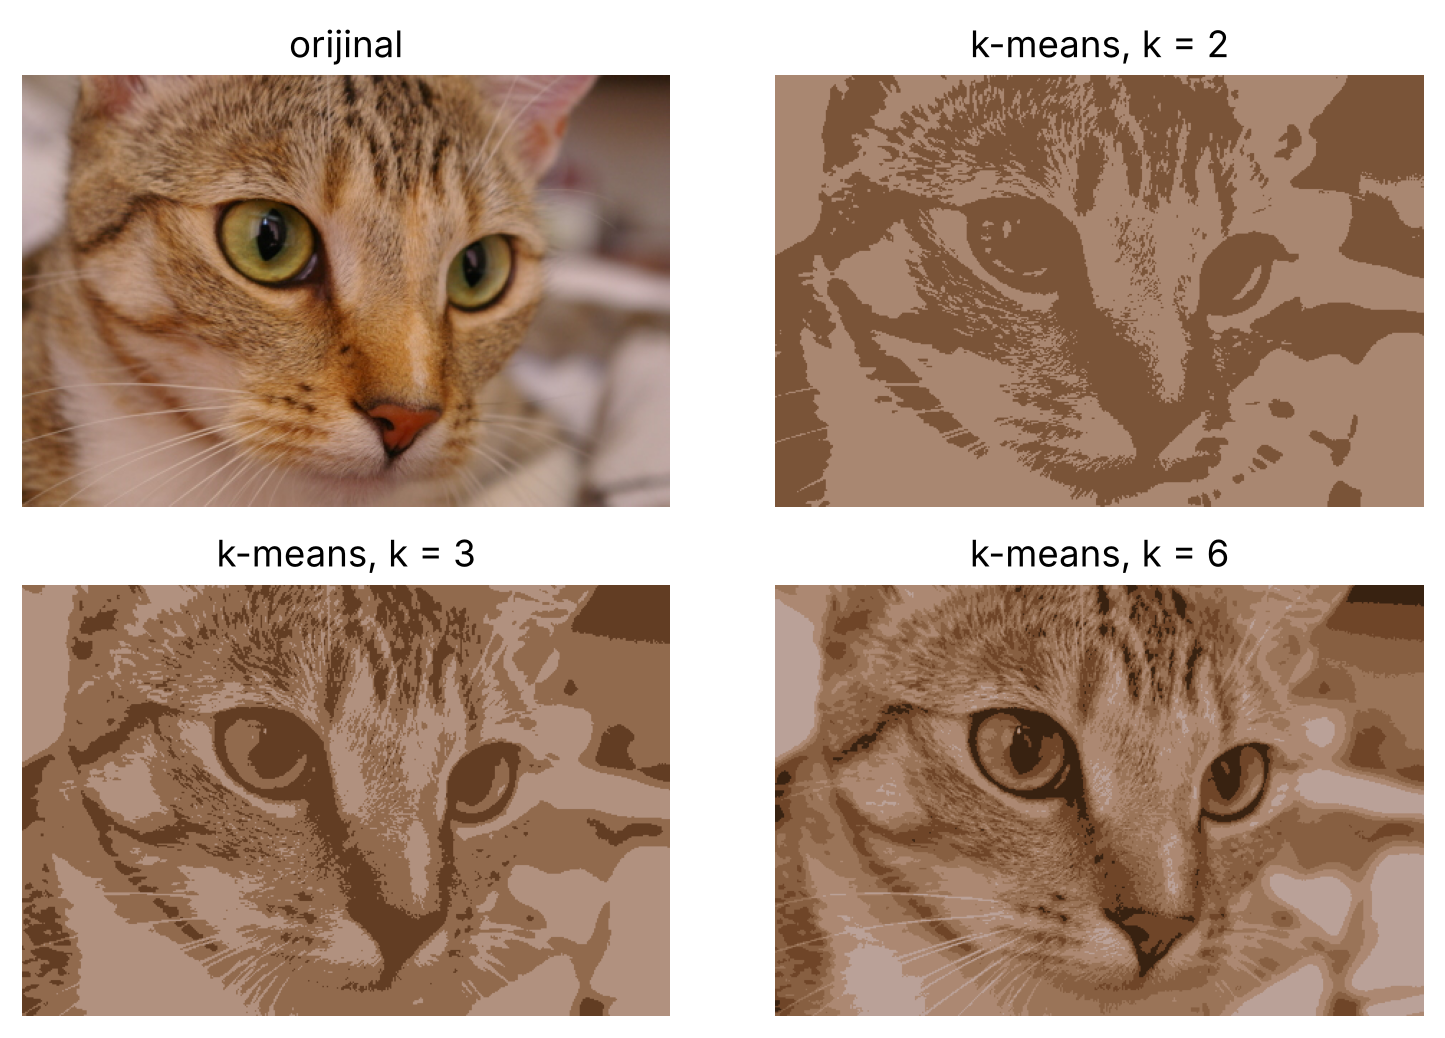

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from sklearn.cluster import KMeans

kedi = data.chelsea()                  # 300 x 451 x 3
pikseller = kedi.reshape(-1, 3) / 255   # piksel = RGB vektörü
print(pikseller.shape)
fig, eksen = plt.subplots(2, 2, figsize=(7, 4.8))
eksen[0, 0].imshow(kedi); eksen[0, 0].set_title("orijinal")
for ax, k in zip(eksen.flat[1:], [2, 3, 6]):
    km = KMeans(k, n_init=3, random_state=0).fit(pikseller)
    renk = km.cluster_centers_[km.labels_]  # merkez rengi
    ax.imshow(renk.reshape(kedi.shape))
    ax.set_title(f"k-means, k = {k}")
for ax in eksen.flat:
    ax.axis("off")
plt.tight_layout(); plt.show()

### Havza (watershed) ile madeni paraları ayırmak (Şekil 11.1)
Gradyan büyüklüğü “arazi”, kesin arka plan ve kesin para pikselleri “su kaynağı” (işaretçi) olur.

bileşen: 25
en küçük 3 alan: [2, 1077, 1103]
para (alan > 50): 24


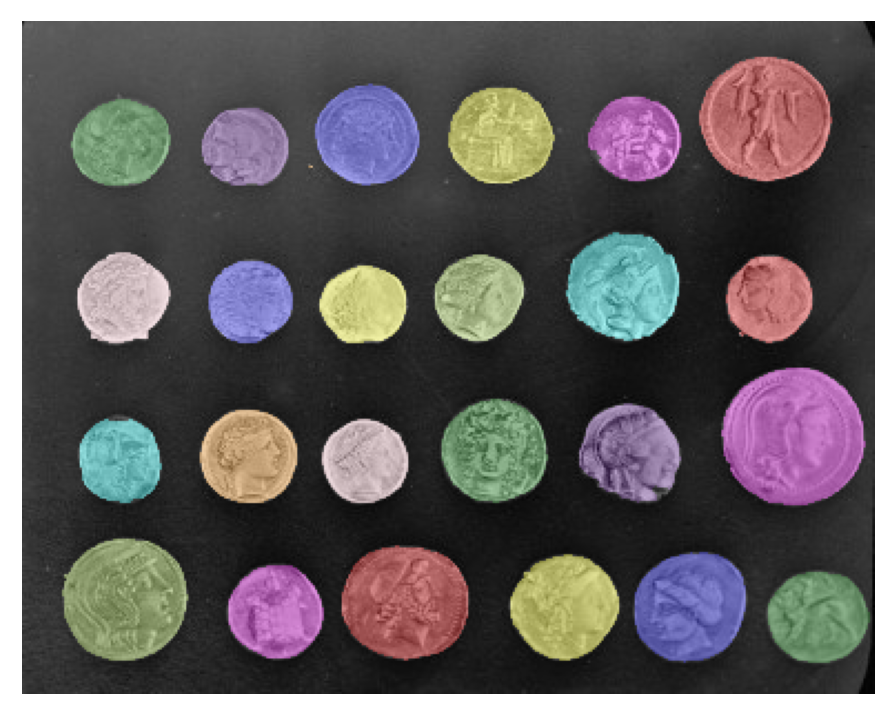

In [3]:
from skimage import filters, segmentation, color
from scipy import ndimage as ndi

para = data.coins()
egim = filters.sobel(para)                 # arazi: gradyan büyüklüğü
isaret = np.zeros_like(para)
isaret[para < 30] = 1                      # kesin arka plan tohumu
isaret[para > 150] = 2                     # kesin para tohumu
havza = segmentation.watershed(egim, isaret)  # su bas
maske = ndi.binary_fill_holes(havza == 2)
etiket, n = ndi.label(maske)
alan = np.bincount(etiket.ravel())[1:]
print("bileşen:", n)
print("en küçük 3 alan:", sorted(alan.tolist())[:3])
print("para (alan > 50):", (alan > 50).sum())
plt.figure(figsize=(5, 4))
plt.imshow(color.label2rgb(etiket, para, bg_label=0))
plt.axis("off"); plt.show()

## 2. Transpoze evrişim (Çözümlü Örnek 11.1)
Çekirdek değerlerini elle verip PyTorch'un sonucunu elle yaptığımız hesapla karşılaştırıyoruz.

In [4]:
import torch
from torch import nn

X = torch.tensor([[1., 2.], [3., 4.]]).view(1, 1, 2, 2)  # 2x2
ters_a = nn.ConvTranspose2d(1, 1, 2, stride=2, bias=False)
ters_b = nn.ConvTranspose2d(1, 1, 2, stride=1, bias=False)
with torch.no_grad():
    ters_a.weight[0, 0] = torch.tensor([[1., 0.], [0., 1.]])
    ters_b.weight[0, 0] = torch.ones(2, 2)         # birler
    print("(a) adım 2 -> 4x4:")
    print(ters_a(X)[0, 0].numpy().astype(int))
    print("(b) adım 1 -> 3x3:")
    print(ters_b(X)[0, 0].numpy().astype(int))

(a) adım 2 -> 4x4:
[[1 0 2 0]
 [0 1 0 2]
 [3 0 4 0]
 [0 3 0 4]]
(b) adım 1 -> 3x3:
[[ 1  3  2]
 [ 4 10  6]
 [ 3  7  4]]


## 3. PyTorch ile küçük bir U-Net
U-Net'in yapı taşı: iki kez 3 × 3 evrişim + toplu normalizasyon + ReLU.

In [5]:
def cift_evrisim(c_girdi, c_cikti):        # U-Net'in yapı taşı
    return nn.Sequential(
        nn.Conv2d(c_girdi, c_cikti, 3, padding=1),
        nn.BatchNorm2d(c_cikti), nn.ReLU(),
        nn.Conv2d(c_cikti, c_cikti, 3, padding=1),
        nn.BatchNorm2d(c_cikti), nn.ReLU())

In [6]:
class MiniUNet(nn.Module):
    def __init__(self, kanal=1, sinif=1):
        super().__init__()
        self.kod1 = cift_evrisim(kanal, 32)        # kodlayıcı: H x W
        self.kod2 = cift_evrisim(32, 64)           # H/2 x W/2
        self.darbogaz = cift_evrisim(64, 128)      # H/4 x W/4
        self.havuz = nn.MaxPool2d(2)
        self.yukari2 = nn.ConvTranspose2d(128, 64, 2, stride=2)  # 2 kat büyüt
        self.coz2 = cift_evrisim(128, 64)          # 64 atlama + 64 yukarı
        self.yukari1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.coz1 = cift_evrisim(64, 32)
        self.cikis = nn.Conv2d(32, sinif, 1)       # piksel başına skor
    def forward(self, x):
        a1 = self.kod1(x)
        a2 = self.kod2(self.havuz(a1))
        d = self.darbogaz(self.havuz(a2))
        u2 = self.coz2(torch.cat([self.yukari2(d), a2], dim=1))   # atlama
        u1 = self.coz1(torch.cat([self.yukari1(u2), a1], dim=1))  # atlama
        return self.cikis(u1)                      # H x W logit maskesi

### Katman katman boyut takibi

In [7]:
model = MiniUNet()
x = torch.randn(4, 1, 128, 128)               # 4 gri kesit
a1 = model.kod1(x)
a2 = model.kod2(model.havuz(a1))
d = model.darbogaz(model.havuz(a2))
u2 = model.coz2(torch.cat([model.yukari2(d), a2], 1))
u1 = model.coz1(torch.cat([model.yukari1(u2), a1], 1))
katmanlar = [("girdi", x), ("kod1", a1), ("kod2", a2),
             ("darboğaz", d), ("çöz2", u2), ("çöz1", u1),
             ("çıkış", model.cikis(u1))]
for ad, t in katmanlar:
    print(f"{ad:9s}", tuple(t.shape))
print("parametre:", sum(p.numel() for p in model.parameters()))

girdi     (4, 1, 128, 128)
kod1      (4, 32, 128, 128)
kod2      (4, 64, 64, 64)
darboğaz  (4, 128, 32, 32)
çöz2      (4, 64, 64, 64)
çöz1      (4, 32, 128, 128)
çıkış     (4, 1, 128, 128)
parametre: 467233


### Sentetik veride kısa bir eğitim
Gürültülü arka plan üzerinde parlak diskler üretip MiniUNet'i çapraz entropi + Dice kaybıyla eğitiyoruz.

In [8]:
def dice_kaybi(logit, hedef, eps=1.0):
    p = torch.sigmoid(logit)                    # olasılık
    kesisim = (p * hedef).sum(dim=(1, 2, 3))
    toplam = p.sum(dim=(1, 2, 3)) + hedef.sum(dim=(1, 2, 3))
    return 1 - ((2 * kesisim + eps) / (toplam + eps)).mean()

In [9]:
def disk_verisi(n, boyut=64):
    """Gürültülü zeminde rastgele disk ve maskesi."""
    a = torch.arange(boyut)
    yy, xx = torch.meshgrid(a, a, indexing="ij")
    merkez = torch.randint(16, boyut - 16, (n, 2, 1, 1))
    mx, my = merkez[:, :1], merkez[:, 1:]
    r = torch.randint(6, 14, (n, 1, 1, 1))
    Y = ((xx - mx) ** 2 + (yy - my) ** 2 < r ** 2).float()
    X = 0.8 * Y + 0.35 * torch.randn_like(Y)   # disk + gürültü
    return X, Y

torch.manual_seed(0)
Xe, Ye = disk_verisi(64)                          # eğitim
Xt, Yt = disk_verisi(16)                          # test
print("eğitim:", tuple(Xe.shape))
print("test  :", tuple(Xt.shape))
print("nesne pikseli oranı:", round(Ye.mean().item(), 3))

eğitim: (64, 1, 64, 64)
test  : (16, 1, 64, 64)
nesne pikseli oranı: 0.064


In [10]:
model = MiniUNet()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
bce = nn.BCEWithLogitsLoss()
for adim in range(1, 61):
    i = torch.randint(0, 64, (8,))          # 8'lik mini-yığın
    cikti = model(Xe[i])
    kayip = bce(cikti, Ye[i]) + dice_kaybi(cikti, Ye[i])
    opt.zero_grad(); kayip.backward(); opt.step()
    if adim % 15 == 0:
        print(f"adım {adim:2d}: kayıp = {kayip.item():.3f}")

adım 15: kayıp = 1.052


adım 30: kayıp = 1.088


adım 45: kayıp = 0.891


adım 60: kayıp = 0.736


test Dice: 0.955


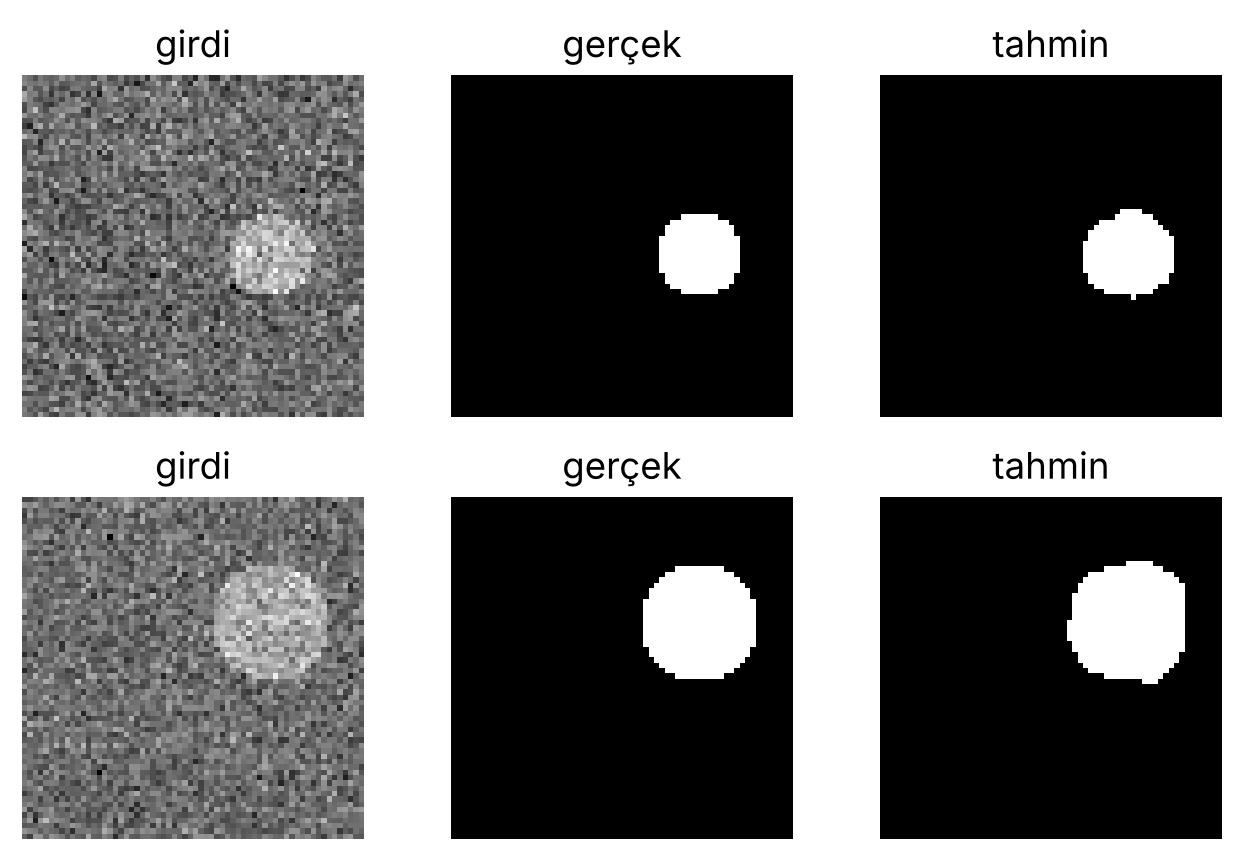

In [11]:
model.eval()
with torch.no_grad():
    olas = torch.sigmoid(model(Xt))     # piksel olasılığı
T = (olas > 0.5).float()                # 0.5 eşiği -> maske
dice = 2 * (T * Yt).sum() / (T.sum() + Yt.sum())
print("test Dice:", round(dice.item(), 3))
basliklar = ["girdi", "gerçek", "tahmin"]
fig, eksen = plt.subplots(2, 3, figsize=(6, 4))
for s in range(2):
    resimler = [Xt[s, 0], Yt[s, 0], T[s, 0]]
    for ax, g, b in zip(eksen[s], resimler, basliklar):
        ax.imshow(g, cmap="gray"); ax.axis("off")
        ax.set_title(b)
plt.tight_layout(); plt.show()

## 4. Diğer mimariler
### Genişletilmiş (atrous) evrişim: aynı 9 ağırlık, daha geniş alan (DeepLab)
Ortasında tek bir 1 olan görüntüye birlerden oluşan 3 × 3 çekirdek uygulanır; çıktıdaki sıfır olmayan konumlar çekirdeğin hangi pikselleri gördüğünü gösterir.

In [12]:
x = torch.zeros(1, 1, 9, 9); x[0, 0, 4, 4] = 1     # ortada tek bir 1
for r in [1, 2, 3]:
    conv = nn.Conv2d(1, 1, 3, dilation=r, padding=r, bias=False)
    nn.init.ones_(conv.weight)
    y = conv(x)[0, 0].detach()
    print(f"r = {r}: ağırlık = {conv.weight.numel()}, çıktı = {tuple(y.shape)},",
          f"kapsanan alan = {2 * r + 1}x{2 * r + 1}")
print((conv(x)[0, 0] > 0).int())                   # r = 3 için örnekleme deseni

r = 1: ağırlık = 9, çıktı = (9, 9), kapsanan alan = 3x3
r = 2: ağırlık = 9, çıktı = (9, 9), kapsanan alan = 5x5
r = 3: ağırlık = 9, çıktı = (9, 9), kapsanan alan = 7x7
tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0]], dtype=torch.int32)


### Hazır segmentasyon modellerinin büyüklüğü
Ağırlıksız kurulum (weights=None) parametre sayısını değiştirmez; Colab'da önceden eğitilmiş ağırlıklar için `weights="DEFAULT"` yazabilirsiniz.

In [13]:
from torchvision.models import segmentation as seg, detection as det
say = lambda m: sum(p.numel() for p in m.parameters())
kur = dict(weights=None, weights_backbone=None)    # ağırlıksız kurulum
modeller = {
    "FCN (ResNet-50)": seg.fcn_resnet50(**kur),
    "DeepLabv3 (ResNet-50)": seg.deeplabv3_resnet50(**kur),
    "DeepLabv3 (MobileNetV3)": seg.deeplabv3_mobilenet_v3_large(**kur),
    "Mask R-CNN (R50-FPN)": det.maskrcnn_resnet50_fpn(**kur),
    "MiniUNet (bu defter)": MiniUNet(),
}
for ad, m in modeller.items():
    print(f"{ad:24s} {say(m) / 1e6:6.2f} M parametre")
fcn = modeller["FCN (ResNet-50)"].eval()
with torch.no_grad():
    cikti = fcn(torch.randn(1, 3, 256, 256))["out"]
print("FCN çıktısı:", tuple(cikti.shape))   # 21 sınıf skoru

FCN (ResNet-50)           32.96 M parametre
DeepLabv3 (ResNet-50)     39.64 M parametre
DeepLabv3 (MobileNetV3)   11.03 M parametre
Mask R-CNN (R50-FPN)      44.45 M parametre
MiniUNet (bu defter)       0.47 M parametre


FCN çıktısı: (1, 21, 256, 256)


### Ek: tam boy U-Net (64 → 1024 kanal) kaç parametre?
Orijinal makaledeki kanal sayılarıyla (dolgulu evrişim ve toplu normalizasyonla) bir U-Net kurup sayıyoruz.

In [14]:
class UNet(nn.Module):
    def __init__(self, kanal=1, sinif=2, t=64):
        super().__init__()
        c = [t, 2 * t, 4 * t, 8 * t, 16 * t]                     # 64 ... 1024
        self.kod = nn.ModuleList([cift_evrisim(kanal, c[0])] + [cift_evrisim(c[i], c[i + 1]) for i in range(4)])
        self.yukari = nn.ModuleList([nn.ConvTranspose2d(c[i + 1], c[i], 2, stride=2) for i in reversed(range(4))])
        self.coz = nn.ModuleList([cift_evrisim(2 * c[i], c[i]) for i in reversed(range(4))])
        self.havuz, self.cikis = nn.MaxPool2d(2), nn.Conv2d(t, sinif, 1)
    def forward(self, x):
        atlama = []
        for i, k in enumerate(self.kod):
            x = k(x if i == 0 else self.havuz(x)); atlama.append(x)
        x = atlama.pop()
        for y, c_ in zip(self.yukari, self.coz):
            x = c_(torch.cat([y(x), atlama.pop()], dim=1))
        return self.cikis(x)

u = UNet()
print("U-Net parametre:", sum(p.numel() for p in u.parameters()))
print("çıktı:", tuple(u(torch.randn(1, 1, 256, 256)).shape))

U-Net parametre: 31042434


çıktı: (1, 2, 256, 256)


## 5. Segmentasyon metrikleri
### IoU, Dice ve piksel doğruluğu (Çözümlü Örnek 11.2)

In [15]:
G = np.zeros((5, 5), bool); G[1:4, 1:4] = True  # gerçek: 9
P = np.zeros((5, 5), bool); P[1:3, 2:5] = True  # tahmin
P[3, 1:5] = True                                # toplam 10
TP, FP = (G & P).sum(), (~G & P).sum()
FN, TN = (G & ~P).sum(), (~G & ~P).sum()
print("TP FP FN TN:", TP, FP, FN, TN)
print("IoU  :", round(TP / (TP + FP + FN), 3))
print("Dice :", round(2 * TP / (2 * TP + FP + FN), 3))
print("Doğruluk:", (TP + TN) / G.size)

TP FP FN TN: 7 3 2 13
IoU  : 0.583
Dice : 0.737
Doğruluk: 0.8


### mIoU (Çözümlü Örnek 11.3)

In [16]:
K = np.array([[50, 3, 2],        # satır: gerçek
              [4, 25, 1],        # sütun: tahmin
              [1, 1, 13]])
tp = np.diag(K)
iou_s = tp / (K.sum(1) + K.sum(0) - tp)
print("IoU :", iou_s.round(3))
print("mIoU:", round(iou_s.mean(), 3))
print("Piksel doğruluğu:", tp.sum() / K.sum())

IoU : [0.833 0.735 0.722]
mIoU: 0.764
Piksel doğruluğu: 0.88


### Yumuşak Dice kaybı (Çözümlü Örnek 11.4)

In [17]:
p = np.array([0.9, 0.8, 0.2, 0.1]); g = np.array([1, 1, 0, 0])
dice = 2 * (p * g).sum() / (p.sum() + g.sum())  # Örnek 11.4
print("yumuşak Dice:", round(dice, 3))
print("Dice kaybı  :", round(1 - dice, 3))

yumuşak Dice: 0.85
Dice kaybı  : 0.15


## 6. Son işleme: bağlantılı bileşen analizi
### 4- ve 8-komşuluk (Çözümlü Örnek 11.5)

In [18]:
M = np.array([[1, 1, 0, 0, 1],
              [1, 0, 0, 1, 0],
              [0, 0, 1, 0, 0],
              [0, 1, 0, 0, 0]])              # Örnek 11.5
dort = ndi.generate_binary_structure(2, 1)   # yatay/dikey
sekiz = ndi.generate_binary_structure(2, 2)  # çaprazlar dahil
e4, n4 = ndi.label(M, structure=dort)
e8, n8 = ndi.label(M, structure=sekiz)
print("4-komşuluk:", n4, "bileşen"); print(e4)
print("8-komşuluk:", n8, "bileşen"); print(e8)

4-komşuluk: 5 bileşen
[[1 1 0 0 2]
 [1 0 0 3 0]
 [0 0 4 0 0]
 [0 5 0 0 0]]
8-komşuluk: 2 bileşen
[[1 1 0 0 2]
 [1 0 0 2 0]
 [0 0 2 0 0]
 [0 2 0 0 0]]


### Eşikleme + bağlantılı bileşenlerle saymak
Otsu eşiklemesi gürültülü küçük parçalar da üretir; alanı küçük bileşenleri atmak tipik bir son işleme adımıdır. En büyük bileşene dikkat!

In [19]:
maske2 = para > filters.threshold_otsu(para)  # Otsu
etiket2, n2 = ndi.label(maske2)
alan2 = np.bincount(etiket2.ravel())[1:]      # alanlar
print("bileşen sayısı     :", n2)
print("100 pikselden büyük:", (alan2 > 100).sum())
print("en büyük 3 alan    :", sorted(alan2.tolist())[-3:])

bileşen sayısı     : 154
100 pikselden büyük: 24
en büyük 3 alan    : [2459, 3054, 8755]


## 7. Uygulama: göz dibi fotoğrafında damar segmentasyonu (klasik yöntem)
Frangi süzgeci ince, koyu boru biçimli yapıları (damarları) vurgular; en güçlü yanıtların %12'si damar sayılır.

damar pikseli oranı: 0.075


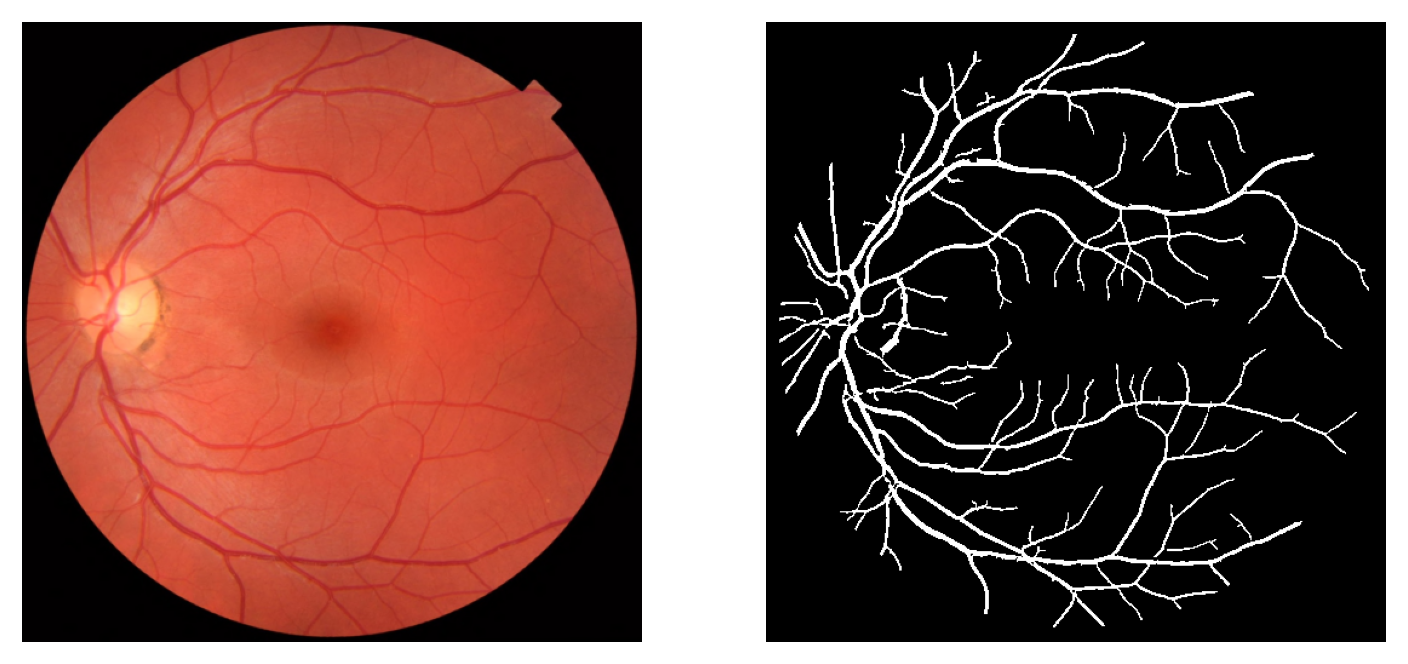

In [20]:
from skimage import transform, morphology
ret = transform.resize(data.retina(), (512, 512), anti_aliasing=True)
gorus = morphology.erosion(ret.sum(-1) > 0.25, morphology.disk(8))  # göz dibi alanı
skor = filters.frangi(ret[..., 1], sigmas=range(1, 5), black_ridges=True)
skor[~gorus] = 0
damar = (skor > np.percentile(skor[gorus], 88)) & gorus
et, _ = ndi.label(damar)
damar = (np.bincount(et.ravel())[et] > 40) & (et > 0)        # küçük parçaları at
print("damar pikseli oranı:", round(damar.mean(), 3))
fig, eksen = plt.subplots(1, 2, figsize=(8, 4))
eksen[0].imshow(ret); eksen[1].imshow(damar, cmap="gray")
for ax in eksen: ax.axis("off")
plt.show()

### Alıştırma (Değerlendirme Soruları 7, 10 ve 11)
Önce kâğıt üzerinde çözün, sonra hücreyi çalıştırıp karşılaştırın.

In [ ]:
kesisim, g_alan, p_alan = 80, 120, 100                       # Soru 7
print("Soru 7  IoU:", round(kesisim / (g_alan + p_alan - kesisim), 3),
      "| Dice:", round(2 * kesisim / (g_alan + p_alan), 3))
K2 = np.array([[80, 5], [3, 12]])                            # Soru 10
tp2 = np.diag(K2)
iou2 = tp2 / (K2.sum(1) + K2.sum(0) - tp2)
print("Soru 10 IoU:", iou2.round(3), "| mIoU:", round(iou2.mean(), 3),
      "| doğruluk:", tp2.sum() / K2.sum())
w = 100 / (2 * np.array([95, 5]))                            # Soru 11
print("Soru 11 ağırlıklar:", w.round(3), "| lezyon kaybı:", round(-w[1] * np.log(0.6), 2),
      "| arka plan kaybı:", round(-w[0] * np.log(0.99), 4))